In [1]:
# Cell 1: Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
# Cell 2: Load CIFAR-10 Dataset

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Dataset loaded successfully!")

print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2877s 17us/step
Dataset loaded successfully!
Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing images shape: (10000, 32, 32, 3)
Testing labels shape: (10000, 1)


In [3]:
# Cell 3: Define Class Names

class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

print("Total classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, ":", name)

Total classes: 10
0 : Airplane
1 : Automobile
2 : Bird
3 : Cat
4 : Deer
5 : Dog
6 : Frog
7 : Horse
8 : Ship
9 : Truck


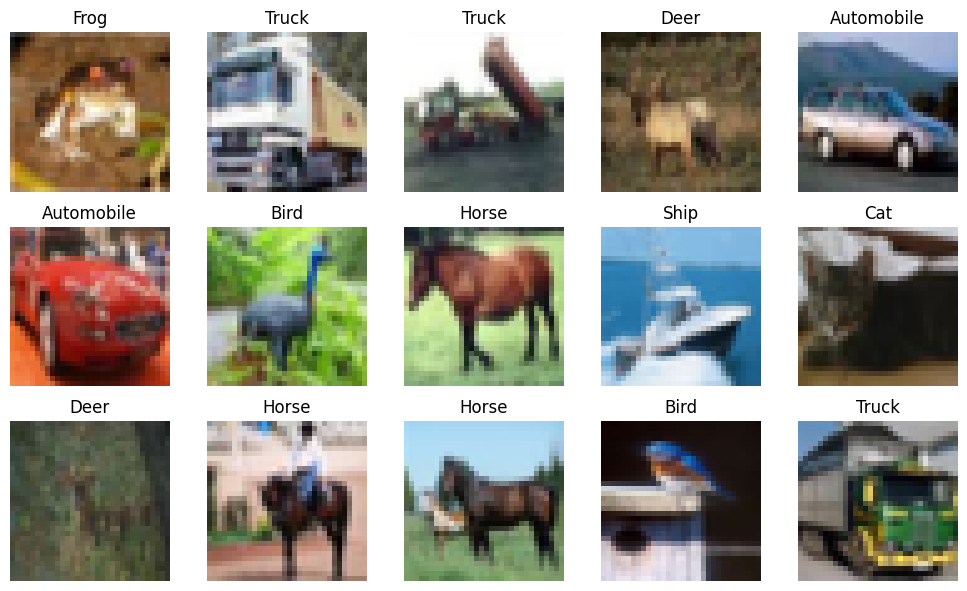

In [4]:
# Cell 4: Visualize Sample Images

plt.figure(figsize=(10, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[i])
    label = int(y_train[i][0])

    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Cell 5: Normalize Image Data

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Image normalization completed!")

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Image normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [6]:
# Cell 6: One-Hot Encode Labels

y_train_encoded = to_categorical(y_train, num_classes=10)
y_test_encoded = to_categorical(y_test, num_classes=10)

print("Label encoding completed!")

print("Original label:", y_train[0][0])
print("Encoded label:", y_train_encoded[0])

Label encoding completed!
Original label: 6
Encoded label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


In [7]:
# Cell 7: Data Augmentation

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


In [8]:
# Cell 8: Build CNN Model

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Fully connected classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

print("CNN model created successfully!")

CNN model created successfully!


In [9]:
# Cell 9: Display Model Summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,986 (1.54 MB)

 Trainable params: 402,986 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Cell 10: Compile CNN Model

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [11]:
# Cell 11: Train CNN Model

history = model.fit(
    X_train,
    y_train_encoded,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

print("Model training completed!")

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 222s 350ms/step - accuracy: 0.3292 - loss: 1.8097 - val_accuracy: 0.4677 - val_loss: 1.4581
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 224s 359ms/step - accuracy: 0.4724 - loss: 1.4493 - val_accuracy: 0.5532 - val_loss: 1.2203
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 221s 353ms/step - accuracy: 0.5468 - loss: 1.2624 - val_accuracy: 0.6337 - val_loss: 1.0176
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 225s 360ms/step - accuracy: 0.6023 - loss: 1.1371 - val_accuracy: 0.6807 - val_loss: 0.9228
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 254s 348ms/step - accuracy: 0.6352 - loss: 1.0467 - val_accuracy: 0.6764 - val_loss: 0.9318
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 262s 348ms/step - accuracy: 0.6632 - loss: 0.9803 - val_accuracy: 0.7220 - val_loss: 0.7934
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 268s 357ms/step - accuracy: 0.6811 - loss: 0.9290 - val_accuracy: 0.7403 - val_loss: 0.7404
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 255s 346ms/step - accuracy: 0.6975 -

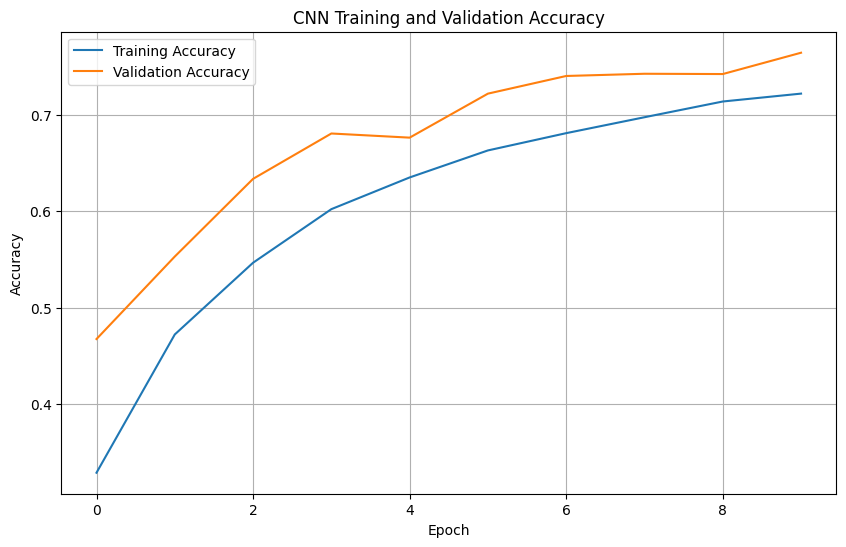

In [12]:
# Cell 12: Plot Accuracy Curves

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

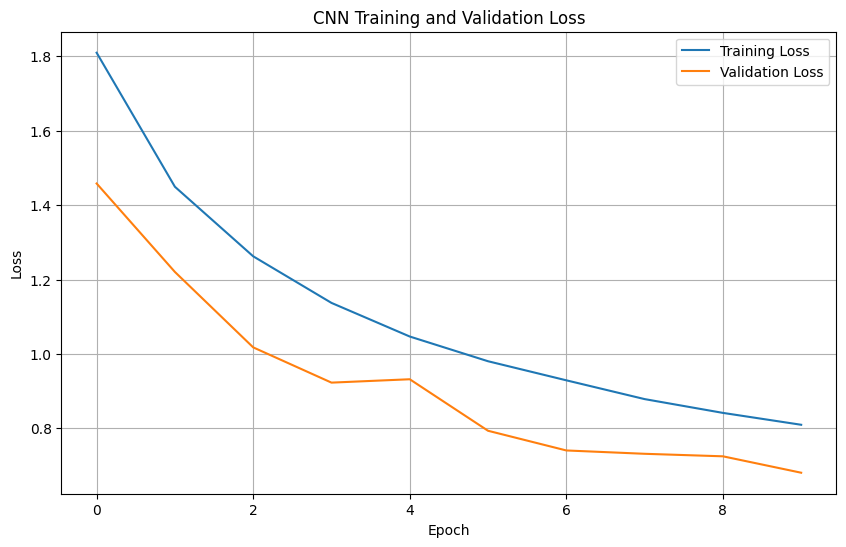

In [13]:
# Cell 13: Plot Loss Curves

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Cell 14: Evaluate CNN Model

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print("\n========== TEST RESULTS ==========")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")
print("==================================")

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.7582 - loss: 0.7053

========== TEST RESULTS ==========
Test Loss: 0.7053
Test Accuracy: 0.7582
Test Accuracy Percentage: 75.82%


In [15]:
# Cell 15: Predict Sample Images

predictions = model.predict(X_test[:10])

predicted_classes = np.argmax(predictions, axis=1)
actual_classes = y_test[:10].flatten()

for i in range(10):
    print("Image", i + 1)
    print("Actual class:", class_names[actual_classes[i]])
    print("Predicted class:", class_names[predicted_classes[i]])
    print("Confidence:", f"{np.max(predictions[i]) * 100:.2f}%")
    print("-" * 30)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
Image 1
Actual class: Cat
Predicted class: Cat
Confidence: 58.26%
------------------------------
Image 2
Actual class: Ship
Predicted class: Ship
Confidence: 99.99%
------------------------------
Image 3
Actual class: Ship
Predicted class: Ship
Confidence: 98.57%
------------------------------
Image 4
Actual class: Airplane
Predicted class: Airplane
Confidence: 79.33%
------------------------------
Image 5
Actual class: Frog
Predicted class: Frog
Confidence: 99.93%
------------------------------
Image 6
Actual class: Frog
Predicted class: Frog
Confidence: 96.60%
------------------------------
Image 7
Actual class: Automobile
Predicted class: Automobile
Confidence: 82.33%
------------------------------
Image 8
Actual class: Frog
Predicted class: Frog
Confidence: 65.09%
------------------------------
Image 9
Actual class: Cat
Predicted class: Cat
Confidence: 73.55%
------------------------------
Image 10
Actual class: Automobile
Predicted class: Tru

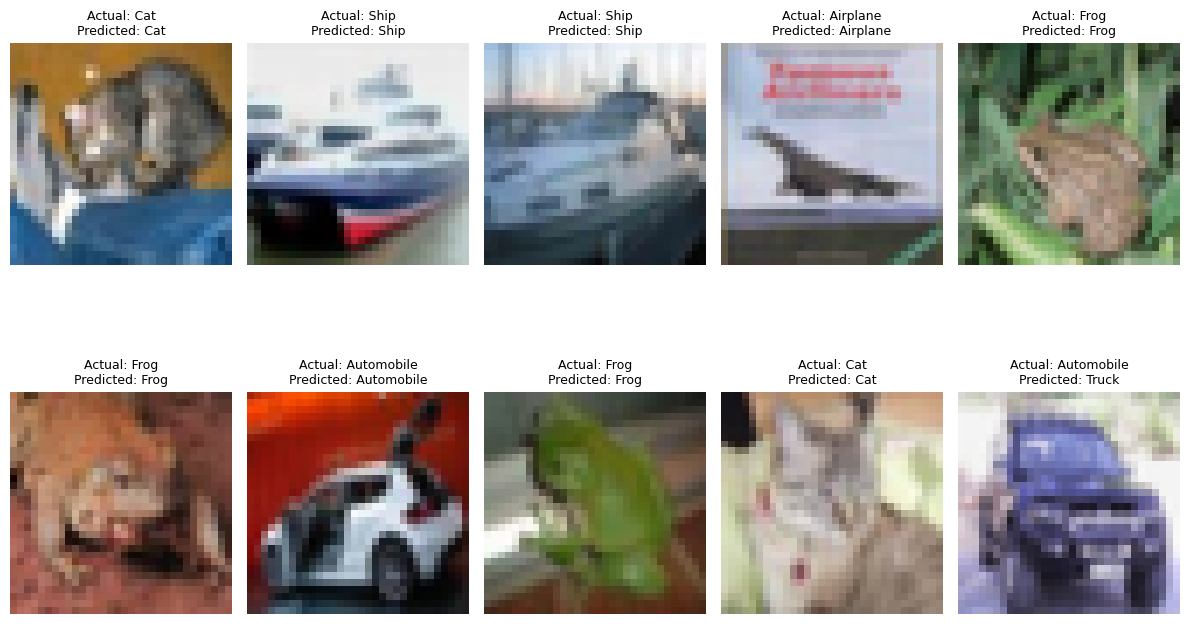

In [16]:
# Cell 16: Display Predictions

plt.figure(figsize=(12, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i])

    actual = class_names[int(y_test[i][0])]
    predicted = class_names[int(predicted_classes[i])]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Cell 17: Save CNN Model

model.save("cifar10_cnn_model.keras")

print("CNN model saved successfully!")
print("File: cifar10_cnn_model.keras")

CNN model saved successfully!
File: cifar10_cnn_model.keras


In [18]:
# Cell 18: Final Task Summary

print("========== TASK 3 COMPLETED ==========")

print("Dataset: CIFAR-10")
print("Number of Classes:", len(class_names))
print("Model: Convolutional Neural Network")
print("Convolutional Layers: Conv2D")
print("Pooling Layers: MaxPooling2D")
print("Fully Connected Layers: Dense")
print("Data Augmentation: Random Flip and Translation")
print("Regularization: Dropout")

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")

print("\nRequired accuracy graphs generated.")
print("Task 3 pipeline completed successfully!")

========== TASK 3 COMPLETED ==========
Dataset: CIFAR-10
Number of Classes: 10
Model: Convolutional Neural Network
Convolutional Layers: Conv2D
Pooling Layers: MaxPooling2D
Fully Connected Layers: Dense
Data Augmentation: Random Flip and Translation
Regularization: Dropout

Test Loss: 0.7053
Test Accuracy: 0.7582
Test Accuracy Percentage: 75.82%

Required accuracy graphs generated.
Task 3 pipeline completed successfully!
